# Credit Card Fraud Detection

**Objective.** Build a classifier that identifies fraudulent credit card transactions in a dataset where only 0.17 % of transactions are fraudulent, and compare four algorithms in a controlled way:

1. Logistic Regression
2. Support Vector Machine (SVM)
3. Decision Tree
4. XGBoost (gradient-boosted trees)

Every algorithm's hyperparameters are tuned by stratified cross-validation, and its decision threshold is then tuned separately. The models are compared on a held-out test set that plays no part in any modelling decision.

**Dataset.** [Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) (ULB Machine Learning Group): 284,807 transactions made by European cardholders over two days in September 2013. For confidentiality, 28 of the features (`V1` to `V28`) are principal components of the original variables. Only `Time` and `Amount` are given in their original form.

**Code organisation.** The notebook explains the reasoning and shows the results. The implementation lives in the `fraud_detection` package next to this notebook, one module per responsibility:

| Module | Responsibility |
|---|---|
| `config.py` | Every constant that controls the experiment (seed, split size, folds, metrics) |
| `data.py` | Loading the CSV and creating the stratified train/test split |
| `preprocessing.py` | Feature transformations and the two imbalance strategies |
| `models.py` | The four algorithms and their hyperparameter search spaces |
| `tuning.py` | Cross-validated hyperparameter search and threshold tuning |
| `evaluation.py` | Fraud-focused metrics and comparison tables |
| `plotting.py` | The charts shown below |

## Changes relative to the first version of this notebook

The first version compared undersampling with no resampling for a logistic regression. This version keeps that question and corrects several methodological issues. Each correction is explained in the section where it applies.

| Issue in the first version | Consequence | Correction |
|---|---|---|
| The undersampled subset was drawn from the whole dataset *before* the train/test split, and the resulting model was then scored on the full test set | Roughly 70 % of the frauds in the test set had already been seen in training, so the reported recall was optimistic | Split first; undersample only inside each training fold |
| `Amount` was standardised on the whole dataset | Statistics of the test set leaked into training | Scaling is a pipeline step fitted on training folds only |
| Hyperparameters were chosen by recall alone | Recall is maximised by predicting fraud for everything, so the search favoured over-eager models | Tune on average precision, then choose the threshold with F2 |
| The decision threshold was compared visually on a handful of fixed values | The model's default cut-off was used for the final predictions | The threshold is chosen by maximising F2 on out-of-fold training predictions |
| Cross-validation used unshuffled, unstratified `KFold` | Folds followed the file's time order and their fraud counts varied | `StratifiedKFold` with shuffling and a fixed seed |
| The precision-recall curve was computed from 0/1 predictions | Each "curve" collapsed to a single point | Curves are computed from continuous scores |
| Removed APIs (`sklearn.cross_validation`, `DataFrame.ix`, `Series.reshape`) | The notebook no longer ran | Current scikit-learn and pandas APIs |
| Only logistic regression was evaluated | No comparison between algorithms | SVM, Decision Tree and XGBoost added, each tuned |

## 1. Setup

The project folder is added to the import path so that the local `fraud_detection` package can be imported. `apply_chart_style` sets consistent chart defaults for the whole notebook.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from fraud_detection import config, data, evaluation, models, plotting, tuning
from fraud_detection.preprocessing import ImbalanceStrategy, build_pipeline

%matplotlib inline
plotting.apply_chart_style()
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 160)

## 2. Loading and inspecting the data

In [2]:
transactions = data.load_transactions()
print(f"{len(transactions):,} transactions, {transactions.shape[1]} columns")
transactions.head()

284,807 transactions, 31 columns


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,...,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.62,0
1,0.0,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,...,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.69,0
2,1.0,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,...,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.66,0
3,1.0,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,...,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.50,0
4,2.0,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,...,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.99,0


The dataset has no missing values, so no imputation is required. `Time` and `Amount` are on very different scales from the PCA components, which are centred around zero.

In [3]:
print(f"Missing values: {int(transactions.isna().sum().sum())}")
transactions[["Time", "Amount", "V1", "V2"]].describe().T

Missing values: 0


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.4814e+04,47488.1460,0.0000,54201.5000,84692.0000,139320.5000,172792.0000
Amount,284807.0,8.8350e+01,250.1201,0.0000,5.6000,22.0000,77.1650,25691.1600
V1,284807.0,1.1752e-15,1.9587,-56.4075,-0.9204,0.0181,1.3156,2.4549
V2,284807.0,3.3850e-16,1.6513,-72.7157,-0.5985,0.0655,0.8037,22.0577


### 2.1 Class balance

,transactions,share_percent
class,,
Legitimate (0),284315,99.827
Fraud (1),492,0.173


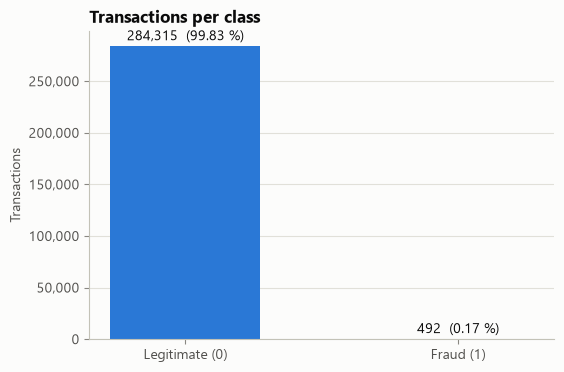

In [4]:
features, target = data.split_features_target(transactions)
class_balance = data.describe_class_balance(target)
display(class_balance)

plotting.plot_class_distribution(class_balance)
plt.show()

The classes are severely imbalanced: there are about 578 legitimate transactions for every fraud. This has two consequences that shape the rest of the notebook.

**Accuracy is not a useful metric.** A model that never predicts fraud is almost perfectly accurate and catches nothing:

In [5]:
majority_class_accuracy = (target == 0).mean()
print(f"Accuracy of a model that never predicts fraud: {majority_class_accuracy:.2%}")
print(f"Frauds caught by that model: 0 of {int(target.sum())}")

Accuracy of a model that never predicts fraud: 99.83%
Frauds caught by that model: 0 of 492


**Models need help to take the fraud class seriously.** A learner that minimises total error can reach a very low error rate by ignoring the 0.17 % minority. Section 4 describes two ways to counter this.

### 2.2 Transaction amount

`Amount` ranges from 0 to over 25,000 and is strongly right-skewed. On a logarithmic scale the two classes have visibly different distributions, so the feature is informative. The log transform, applied in preprocessing, also stops a few very large amounts from dominating distance-based models such as the SVM.

Amount: median 22.00, maximum 25,691.16


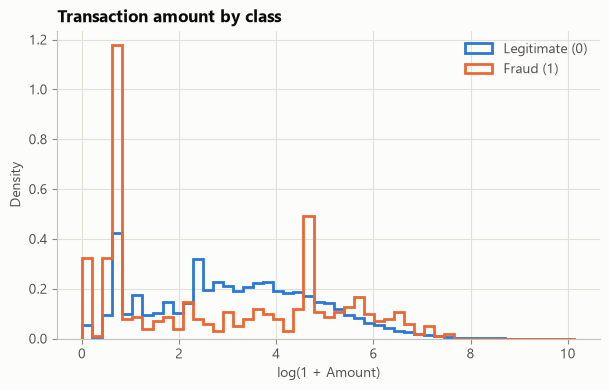

In [6]:
print(f"Amount: median {transactions['Amount'].median():.2f}, maximum {transactions['Amount'].max():,.2f}")
plotting.plot_amount_distribution(transactions)
plt.show()

## 3. Evaluation metrics

Because accuracy is ruled out, the following metrics are used. Each one describes how well the **fraud** class is handled.

| Metric | Definition | Question it answers |
|---|---|---|
| Recall | TP / (TP + FN) | What share of frauds is caught? |
| Precision | TP / (TP + FP) | What share of fraud alerts is genuine? |
| F2 score | Harmonic mean of precision and recall, with recall weighted twice as much | How good is the trade-off when a missed fraud is costlier than a false alarm? |
| Average precision (PR-AUC) | Area under the precision-recall curve | How well does the model rank frauds above legitimate transactions, across all thresholds? |
| ROC-AUC | Area under the ROC curve | The same question, but measured against the false-positive *rate* |

**Why average precision is the tuning metric.** Recall alone can be maximised trivially by flagging every transaction. Average precision does not depend on a threshold and only rewards a model that places frauds ahead of legitimate transactions. ROC-AUC is reported too, but on data this imbalanced it is optimistic: 1,000 false alarms are still a false-positive rate of only about 1 % when there are 85,000 legitimate transactions, so ROC-AUC barely penalises them. Precision counts them directly.

**Why F2 chooses the threshold.** Once a model ranks transactions well, a cut-off still has to be chosen to turn scores into alerts. Missing a fraud costs the full transaction amount, while a false alarm costs an analyst's review or a customer confirmation. F2 encodes that asymmetry (beta = 2 is set in `config.THRESHOLD_BETA`).

## 4. Experimental design

### 4.1 Train/test split

The data is split once into 70 % training and 30 % test, **stratified** by class so that both partitions keep the 0.17 % fraud rate. The split is made *before* any resampling. Every decision below (resampling, hyperparameters, threshold) uses the training partition only, and the test partition is used only for the final evaluation. This ordering matters: the first version of the notebook undersampled the full dataset first, so many test frauds had been seen in training.

In [7]:
split = data.make_train_test_split(features, target)

pd.DataFrame(
    {
        "rows": [len(split.y_train), len(split.y_test)],
        "frauds": [int(split.y_train.sum()), int(split.y_test.sum())],
        "fraud_rate_percent": [split.y_train.mean() * 100, split.y_test.mean() * 100],
    },
    index=["train", "test"],
)

,rows,frauds,fraud_rate_percent
train,199364,344,0.1725
test,85443,148,0.1732


### 4.2 Preprocessing

- **`Time` is dropped.** It counts seconds from the first transaction in this two-day file. It describes a row's position in this extract, not a property of the transaction that would carry over to future data.
- **`Amount` is log-transformed and standardised**, for the reasons given in Section 2.2.
- **`V1` to `V28` are left unchanged**, because they are already PCA outputs on comparable scales.

Tree-based models (Decision Tree, XGBoost) are unaffected by monotonic transformations such as scaling. The same preprocessing is still applied to every model so that all models receive identical inputs.

### 4.3 Imbalance strategies

Two standard strategies are compared:

| Strategy | Mechanism | Advantage | Drawback |
|---|---|---|---|
| **Undersampling** | Legitimate rows are randomly removed from each training fold until both classes are equally frequent | Fast, small training sets; the model sees a balanced problem | About 99.6 % of the legitimate rows are discarded |
| **Class weighting** | All rows are kept; each fraud's error counts about 578 times as much in the loss | Uses all of the data | Training is slower, which rules out the kernel SVM |

SMOTE (synthetic oversampling) is a third option. It is not used here because it creates synthetic points in PCA space that have no direct meaning, and class weighting already lets every model use the full data. It is listed as future work.

### 4.4 Pipelines prevent data leakage

Preprocessing, undersampling and the classifier are combined into a single `imblearn` pipeline. During cross-validation the whole pipeline is refitted on each training fold, so:

- the scaler only ever sees training-fold statistics;
- undersampling is applied to the training fold only, so **every validation fold keeps the true 0.17 % fraud rate**. Validation scores therefore estimate performance on realistic traffic, not on an artificially balanced sample.

The pipeline used for an undersampled logistic regression:

In [8]:
build_pipeline(
    models.LOGISTIC_REGRESSION.build_estimator(ImbalanceStrategy.UNDERSAMPLE, 1.0),
    ImbalanceStrategy.UNDERSAMPLE,
)

,steps,"[('preprocess', ...), ('undersample', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('drop', ...), ('amount', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",Non

In [9]:
training_rows_per_fold = len(split.y_train) * (config.CV_FOLDS - 1) // config.CV_FOLDS
frauds_per_fold = int(split.y_train.sum()) * (config.CV_FOLDS - 1) // config.CV_FOLDS

print(f"Rows in a class-weighted training fold: ~{training_rows_per_fold:,}")
print(f"Rows in an undersampled training fold:  ~{2 * frauds_per_fold:,} ({frauds_per_fold} of each class)")
print(f"Weight of one fraud row under class weighting: ~{tuning.negative_to_positive_ratio(split.y_train):.0f} legitimate rows")

Rows in a class-weighted training fold: ~159,491
Rows in an undersampled training fold:  ~550 (275 of each class)
Weight of one fraud row under class weighting: ~579 legitimate rows


## 5. Models and hyperparameter search

### 5.1 Protocol

For each algorithm and each imbalance strategy it supports:

1. A search over its hyperparameter space is run with **5-fold stratified cross-validation** on the training partition, maximising **average precision**.
2. The best combination is refitted on the full training partition.

Two search methods are used, depending on the shape of the space (`models.SearchMethod`):

- **Grid search** evaluates every combination. It is used for Logistic Regression and the Decision Tree, whose spaces are small and discrete.
- **Randomised search** samples 25 combinations from continuous distributions. It is used for the SVM and XGBoost, which have several continuous parameters. When only a few parameters matter, random sampling explores their useful values more thoroughly than a grid with the same budget.

Learning rates, `C` and `gamma` are sampled on a **log-uniform** scale, because the difference between 0.01 and 0.1 matters as much as the difference between 1 and 10.

In [10]:
models.describe_model_specs()

,search_method,imbalance_strategies,tuned_hyperparameters
algorithm,,,
Logistic Regression,grid,"undersampled, class-weighted",C
Support Vector Machine,random,undersampled,"C, gamma, kernel"
Decision Tree,grid,"undersampled, class-weighted","criterion, max_depth, min_samples_leaf"
XGBoost,random,"undersampled, class-weighted","n_estimators, learning_rate, max_depth, min_child_weight, gamma, subsample, colsample_bytree, reg_lambda"


**Running time.** On a 12-core machine the whole notebook runs in about 9 minutes. Most of that is XGBoost on the class-weighted full data. Lower `config.RANDOM_SEARCH_ITERATIONS` for a quicker, less thorough run.

### 5.2 Logistic Regression

**Why this model.** Logistic regression is the linear baseline. It is fast and interpretable, and it shows how much of the problem a linear decision boundary can already solve.

**Hyperparameters.** `C` is the inverse strength of the L2 (ridge) penalty. Smaller values constrain the weights more strongly, which helps when the training set is small, as with undersampling. The grid spans six orders of magnitude, from 0.0001 to 100.

**Why only L2 regularisation.** An earlier run also searched L1 (lasso) regularisation with the `liblinear` solver. L1 never beat the best L2 setting by more than 0.001 in average precision. Some class-weighted L1 fits, however, stalled for several minutes, and that single search took 37 minutes. With only 29 decorrelated PCA features, there is also little for L1's feature selection to remove. The model therefore uses L2 with the `newton-cholesky` solver, which suits data with many more rows than features and fits a class-weighted training fold in seconds.

In [11]:
logistic_results = tuning.tune_all_models((models.LOGISTIC_REGRESSION,), split.X_train, split.y_train)

for result in logistic_results:
    print(f"\nTop 5 combinations - {result.label}")
    display(result.cv_results.head(5))

Logistic Regression (undersampled)            CV average_precision = 0.7746   (7 s)


Logistic Regression (class-weighted)          CV average_precision = 0.7758   (8 s)

Top 5 combinations - Logistic Regression (undersampled)


,C,mean_test_score,std_test_score,rank_test_score
0,0.0010,0.7746,0.0384,1
1,0.0001,0.7709,0.0411,2
2,0.0100,0.7441,0.0500,3
3,0.1000,0.6593,0.1212,4
4,10.0000,0.6347,0.2144,5



Top 5 combinations - Logistic Regression (class-weighted)


,C,mean_test_score,std_test_score,rank_test_score
0,0.01,0.7758,0.0490,1
1,0.10,0.7757,0.0463,2
2,100.00,0.7748,0.0468,3
3,1.00,0.7747,0.0468,4
4,10.00,0.7747,0.0469,5


### 5.3 Support Vector Machine

**Why this model.** An SVM looks for the boundary with the widest margin between the classes. With an RBF kernel it can learn non-linear boundaries, so it tests whether a flexible geometric model improves on the linear baseline.

**Why only undersampling.** Training a kernel SVM costs between O(n²) and O(n³) in the number of rows. A single fit on the ~160,000-row class-weighted training folds would take far too long, and the search needs over a hundred fits. Undersampled folds contain about 550 rows, which keeps the search to seconds. This matches how the SVM would be used in practice on data of this size.

**Hyperparameters.**
- `kernel`: `linear` or `rbf` (radial basis function, non-linear).
- `C`: the penalty for points on the wrong side of the margin. High values fit the training data more tightly.
- `gamma` (RBF only): how far the influence of one training point reaches. High values produce more irregular boundaries.

The SVM outputs a signed distance to the boundary instead of a probability. This distance is used directly as its fraud score (`evaluation.predict_scores`).

In [12]:
svm_results = tuning.tune_all_models((models.SUPPORT_VECTOR_MACHINE,), split.X_train, split.y_train)

for result in svm_results:
    print(f"\nTop 5 combinations - {result.label}")
    display(result.cv_results.head(5))

Support Vector Machine (undersampled)         CV average_precision = 0.7453   (21 s)

Top 5 combinations - Support Vector Machine (undersampled)


,C,gamma,kernel,mean_test_score,std_test_score,rank_test_score
0,0.3587,0.0012,rbf,0.7453,0.0291,1
1,0.2162,0.0004,rbf,0.7453,0.0491,2
2,2.6926,0.0005,rbf,0.7401,0.0444,3
3,0.0107,0.0001,rbf,0.7206,0.0511,4
4,13.8262,0.0006,rbf,0.7187,0.0480,5


### 5.4 Decision Tree

**Why this model.** A decision tree learns a sequence of if/else rules on individual features. It captures interactions and thresholds without any scaling, and the resulting rules can be read directly, which matters when a fraud alert has to be explained.

**Hyperparameters.** A single unrestricted tree memorises its training data, so the search concentrates on controlling complexity:
- `max_depth`: the maximum number of consecutive questions (`None` = unlimited).
- `min_samples_leaf`: the minimum number of training rows in a leaf. Larger values prevent rules that describe only one or two transactions.
- `criterion`: the impurity measure used to choose splits (Gini or entropy).

In [13]:
tree_results = tuning.tune_all_models((models.DECISION_TREE,), split.X_train, split.y_train)

for result in tree_results:
    print(f"\nTop 5 combinations - {result.label}")
    display(result.cv_results.head(5))

Decision Tree (undersampled)                  CV average_precision = 0.3798   (6 s)


Decision Tree (class-weighted)                CV average_precision = 0.7565   (147 s)

Top 5 combinations - Decision Tree (undersampled)


,criterion,max_depth,min_samples_leaf,mean_test_score,std_test_score,rank_test_score
0,gini,5,50,0.3798,0.2225,1
1,gini,8,50,0.3798,0.2225,1
2,gini,12,50,0.3798,0.2225,1
3,gini,None,50,0.3798,0.2225,1
4,gini,3,50,0.3798,0.2225,5



Top 5 combinations - Decision Tree (class-weighted)


,criterion,max_depth,min_samples_leaf,mean_test_score,std_test_score,rank_test_score
0,entropy,8,20,0.7565,0.0162,1
1,entropy,None,20,0.7540,0.0202,2
2,entropy,12,20,0.7538,0.0204,3
3,gini,None,50,0.7508,0.0350,4
4,gini,None,20,0.7501,0.0283,5


### 5.5 XGBoost

**Why this model.** XGBoost builds hundreds of shallow trees in sequence, each one correcting the errors of the trees before it. Gradient-boosted trees are usually the strongest model family on tabular data, and they handle the class-weighted full dataset efficiently with histogram-based splitting.

**Imbalance handling.** XGBoost has no `class_weight` parameter. Its equivalent, `scale_pos_weight`, multiplies the loss of every fraud row. Under class weighting it is set to the ratio of legitimate to fraudulent training rows (~578), as the XGBoost documentation recommends.

**Hyperparameters.**
- `n_estimators` and `learning_rate`: the number of trees, and how much each one contributes. Smaller steps generally need more trees.
- `max_depth`, `min_child_weight`, `gamma`: control the complexity of each tree.
- `subsample` and `colsample_bytree`: the share of rows and features each tree sees. This randomness reduces over-fitting.
- `reg_lambda`: an L2 penalty on leaf values.

In [14]:
xgboost_results = tuning.tune_all_models((models.XGBOOST,), split.X_train, split.y_train)

for result in xgboost_results:
    print(f"\nTop 5 combinations - {result.label}")
    display(result.cv_results.head(5))

XGBoost (undersampled)                        CV average_precision = 0.7657   (22 s)


XGBoost (class-weighted)                      CV average_precision = 0.8640   (273 s)

Top 5 combinations - XGBoost (undersampled)


,colsample_bytree,gamma,learning_rate,max_depth,min_child_weight,n_estimators,reg_lambda,subsample,mean_test_score,std_test_score,rank_test_score
0,0.7244,1.6259,0.1196,7,3,548,0.1409,0.9887,0.7657,0.0220,1
1,0.8447,0.6975,0.0270,7,3,463,0.3489,0.8370,0.7517,0.0601,2
2,0.8011,0.2574,0.0258,2,1,502,1.1018,0.8124,0.7501,0.0531,3
3,0.9433,1.6298,0.0212,3,3,246,0.1112,0.6385,0.7477,0.0711,4
4,0.9772,1.6160,0.0584,2,4,212,0.0157,0.7016,0.7436,0.0679,5



Top 5 combinations - XGBoost (class-weighted)


,colsample_bytree,gamma,learning_rate,max_depth,min_child_weight,n_estimators,reg_lambda,subsample,mean_test_score,std_test_score,rank_test_score
0,0.7218,0.4884,0.1025,5,7,527,0.3059,0.6138,0.8640,0.0294,1
1,0.6988,3.4815,0.1127,6,1,539,0.0129,0.8438,0.8600,0.0173,2
2,0.8447,0.6975,0.0270,7,3,463,0.3489,0.8370,0.8546,0.0257,3
3,0.7244,1.6259,0.1196,7,3,548,0.1409,0.9887,0.8523,0.0283,4
4,0.8282,2.6042,0.2629,6,2,466,3.0635,0.7427,0.8518,0.0291,5


### 5.6 Summary of the searches

Cross-validated average precision of the best combination for every algorithm and strategy:

In [15]:
tuning_results = [*logistic_results, *svm_results, *tree_results, *xgboost_results]
tuning.summarise_tuning(tuning_results)

,cv_average_precision,search_seconds,best_params
model,,,
XGBoost (class-weighted),0.8640,272.9255,"{'colsample_bytree': 0.7218, 'gamma': 0.4884, 'learning_rate': 0.1025, 'max_depth': 5, 'min_child_weight': 7, 'n_estimators': 527, 'reg_lambda': 0.3059, 'su..."
Logistic Regression (class-weighted),0.7758,8.0018,{'C': 0.01}
Logistic Regression (undersampled),0.7746,6.5665,{'C': 0.001}
XGBoost (undersampled),0.7657,21.5275,"{'colsample_bytree': 0.7244, 'gamma': 1.6259, 'learning_rate': 0.1196, 'max_depth': 7, 'min_child_weight': 3, 'n_estimators': 548, 'reg_lambda': 0.1409, 'su..."
Decision Tree (class-weighted),0.7565,146.7006,"{'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 20}"
Support Vector Machine (undersampled),0.7453,20.5246,"{'C': 0.3587, 'gamma': 0.0012, 'kernel': 'rbf'}"
Decision Tree (undersampled),0.3798,5.9568,"{'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 50}"


## 6. Test-set evaluation at the default threshold

Every tuned pipeline is now evaluated once on the held-out test set (85,443 transactions, 148 frauds). Predictions use each model's default decision rule (probability ≥ 0.5, or SVM distance ≥ 0).

In [16]:
default_threshold_models = {result.label: result.best_pipeline for result in tuning_results}
default_comparison = evaluation.build_comparison_table(default_threshold_models, split.X_test, split.y_test)
default_comparison

,recall,precision,f1,f2,average_precision,roc_auc,frauds_caught,frauds_missed,false_alarms
model,,,,,,,,,
XGBoost (class-weighted),0.7973,0.8676,0.8310,0.8104,0.8352,0.9770,118,30,18
Decision Tree (class-weighted),0.8041,0.0717,0.1317,0.2643,0.7534,0.9001,119,29,1540
Logistic Regression (class-weighted),0.8784,0.0651,0.1213,0.2512,0.7032,0.9691,130,18,1866
Logistic Regression (undersampled),0.8041,0.5805,0.6742,0.7465,0.6956,0.9705,119,29,86
Support Vector Machine (undersampled),0.8176,0.3270,0.4672,0.6289,0.6924,0.9708,121,27,249
XGBoost (undersampled),0.8851,0.0558,0.1050,0.2229,0.6716,0.9738,131,17,2216
Decision Tree (undersampled),0.8514,0.0265,0.0514,0.1179,0.3912,0.9463,126,22,4626


**Findings at the default threshold.**

- **Class weighting beat undersampling for every algorithm evaluated both ways.** The gap is largest for the tree models. Test average precision is 0.835 versus 0.672 for XGBoost and 0.753 versus 0.391 for the Decision Tree. For Logistic Regression the two are close (0.703 versus 0.696). Undersampling leaves only about 275 legitimate transactions in each training fold, which is too few to describe what normal behaviour looks like. The undersampled Decision Tree is also very unstable: its cross-validated score varies by ±0.22 between folds.
- **Most models raise thousands of false alarms at the default threshold.** The class-weighted Logistic Regression catches 130 of the 148 test frauds but also flags 1,866 legitimate transactions, a precision of 6.5 %. The undersampled XGBoost has one of the highest recalls (0.885) and 2,216 false alarms. This is why recall cannot be the only criterion: high recall is easy to achieve when false alarms carry no penalty.
- **ROC-AUC hides these differences.** Every model scores between 0.90 and 0.98 on ROC-AUC, while average precision ranges from 0.39 to 0.84.
- The class-weighted XGBoost is the only model whose default threshold already works well: 118 frauds caught with 18 false alarms.

## 7. Decision-threshold tuning

### 7.1 Effect of the threshold

A classifier produces a score, and the threshold turns that score into an alert. The grid below repeats the experiment from the first version of this notebook for the undersampled logistic regression, this time on the realistic test set. Lowering the threshold raises recall and multiplies false alarms.

*This grid only illustrates the trade-off. The threshold is not chosen from it, because choosing on the test set would make the test results optimistic.*

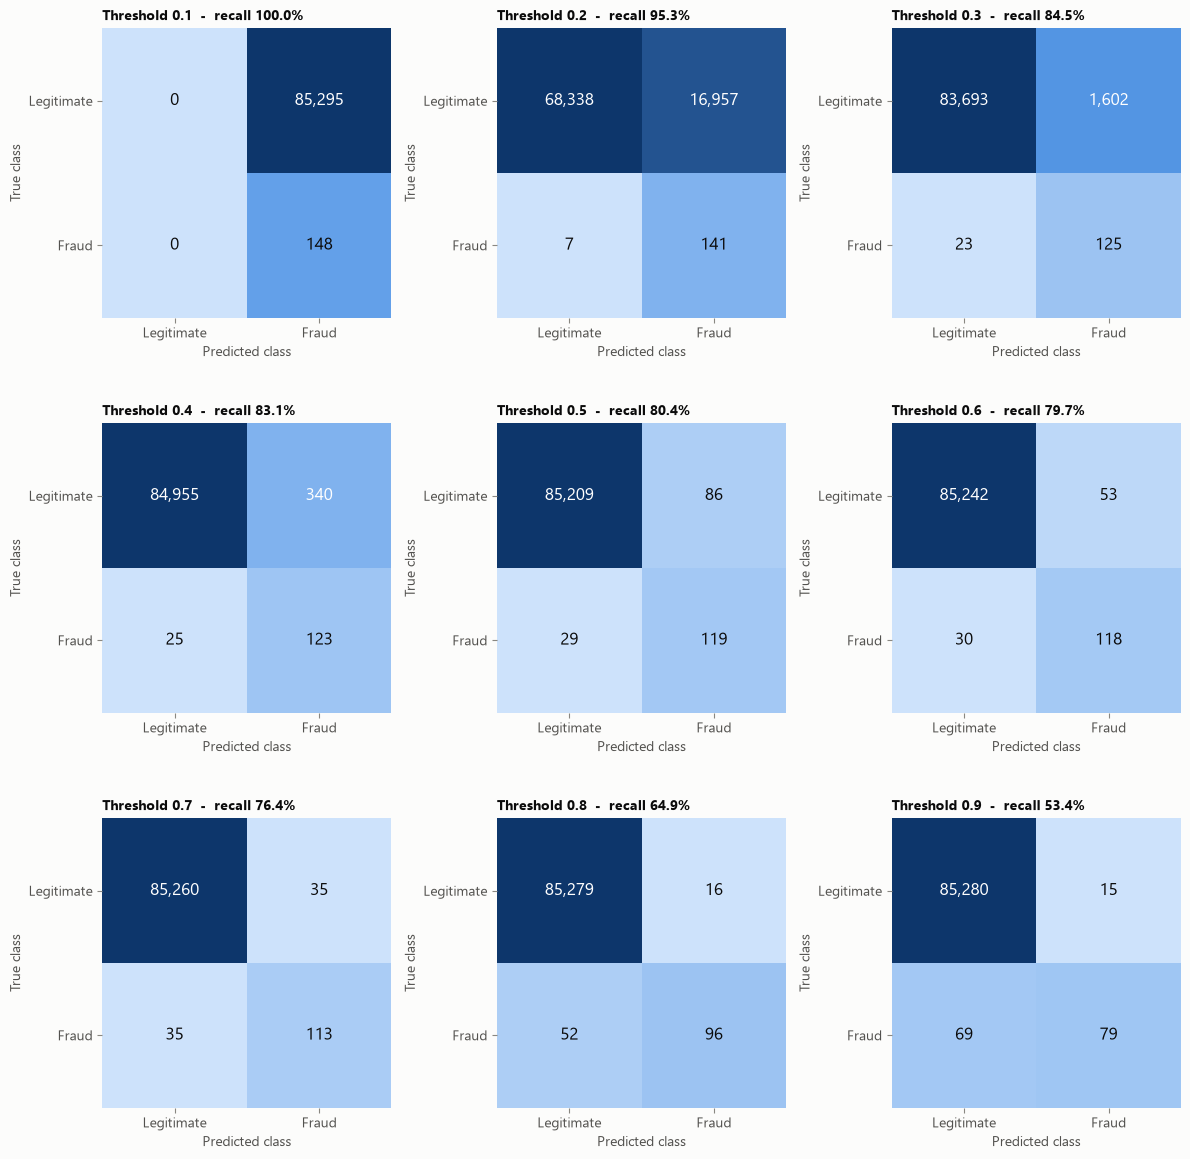

In [17]:
undersampled_logistic = next(
    result for result in logistic_results if result.strategy is ImbalanceStrategy.UNDERSAMPLE
)
plotting.plot_threshold_confusion_grid(undersampled_logistic.best_pipeline, split.X_test, split.y_test)
plt.show()

### 7.2 Choosing the threshold by cross-validation

For each algorithm, the imbalance strategy with the higher **cross-validated** score is kept (the test set is not consulted). Its threshold is then chosen as follows (`tuning.tune_decision_threshold`):

1. Every training row receives an **out-of-fold score**: the pipeline is fitted on four folds and scores the fifth, so no row is scored by a model that saw it during training.
2. Precision, recall and F2 are computed at **every distinct score**. This is an exact search: a grid of fixed candidate thresholds can miss an optimum that lies at 0.998 or beyond, which is common for class-weighted models.
3. The threshold with the highest F2 is kept. The pipeline already fitted on the full training partition is reused, and only its decision rule changes.

Probability thresholds are drawn on a logit axis, which stretches the regions near 0 and 1. The dotted vertical line marks the default threshold.

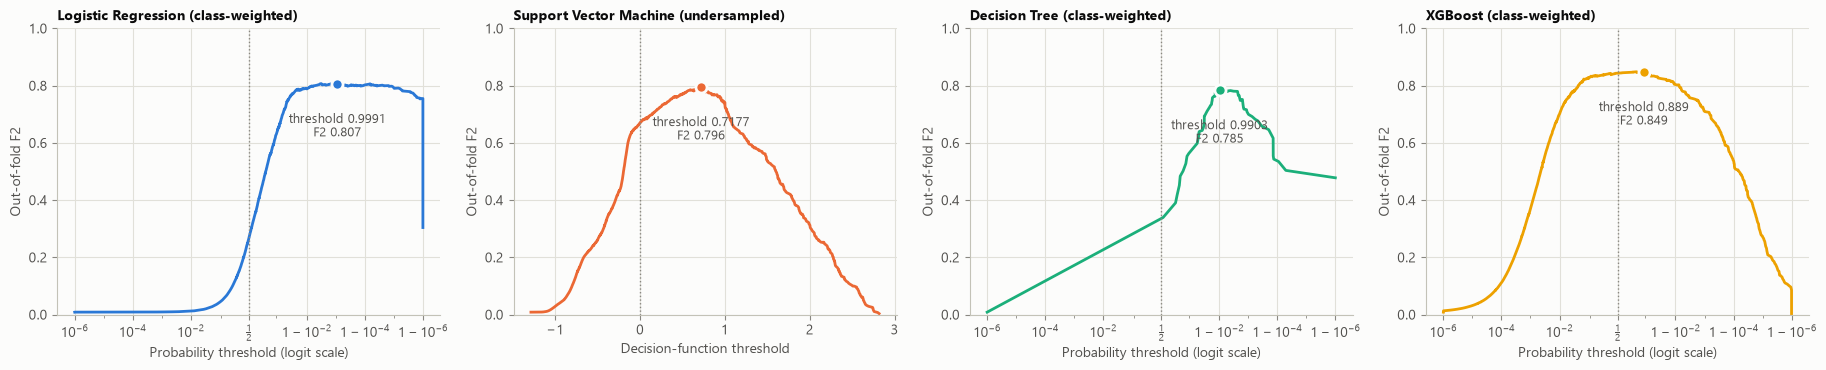

In [18]:
finalists = tuning.select_best_variant_per_algorithm(tuning_results)
threshold_results = [tuning.tune_decision_threshold(result, split.X_train, split.y_train) for result in finalists]
final_models = {result.label: result.classifier for result in threshold_results}

figure, axes = plt.subplots(1, len(threshold_results), figsize=(4.6 * len(threshold_results), 3.8))
for ax, result in zip(axes, threshold_results):
    plotting.plot_threshold_tuning_curve(result, ax=ax)
figure.tight_layout()
plt.show()

### 7.3 Test-set results with tuned thresholds

In [19]:
tuned_comparison = evaluation.build_comparison_table(final_models, split.X_test, split.y_test)
selected_thresholds = {result.label: result.threshold for result in threshold_results}
tuned_comparison.insert(0, "threshold", tuned_comparison.index.map(selected_thresholds))
tuned_comparison

,threshold,recall,precision,f1,f2,average_precision,roc_auc,frauds_caught,frauds_missed,false_alarms
model,,,,,,,,,,
XGBoost (class-weighted),0.8890,0.7838,0.9134,0.8436,0.8067,0.8352,0.9770,116,32,11
Decision Tree (class-weighted),0.9903,0.7703,0.7403,0.7550,0.7641,0.7534,0.9001,114,34,40
Logistic Regression (class-weighted),0.9991,0.7973,0.7195,0.7564,0.7804,0.7032,0.9691,118,30,46
Support Vector Machine (undersampled),0.7177,0.7770,0.6765,0.7233,0.7546,0.6924,0.9708,115,33,55


In [20]:
evaluation.compare_thresholds(default_comparison, tuned_comparison)

default threshold                    \
                                                 recall precision      f2   
model                                                                       
XGBoost (class-weighted)                         0.7973    0.8676  0.8104   
Decision Tree (class-weighted)                   0.8041    0.0717  0.2643   
Logistic Regression (class-weighted)             0.8784    0.0651  0.2512   
Support Vector Machine (undersampled)            0.8176    0.3270  0.6289   

                                                                  \
                                      frauds_caught false_alarms   
model                                                              
XGBoost (class-weighted)                        118           18   
Decision Tree (class-weighted)                  119         1540   
Logistic Regression (class-weighted)            130         1866   
Support Vector Machine (undersampled)           121          249   

                                      tuned threshold                    \
                                               recall precision      f2   
model                                                                     
XGBoost (class-weighted)                       0.7838    0.9134  0.8067   
Decision Tree (class-weighted)                 0.7703    0.7403  0.7641   
Logistic Regression (class-weighted)           0.7973    0.7195  0.7804   
Support Vector Machine (undersampled)          0.7770    0.6765  0.7546   

                                                                  
                                      frauds_caught false_alarms  
model                                                             
XGBoost (class-weighted)                        116           11  
Decision Tree (class-weighted)                  114           40  
Logistic Regression (class-weighted)            118           46  
Support Vector Machine (undersampled)           115           55

**Findings after threshold tuning.**

- **Moving the threshold removed most false alarms, at a small cost in recall.** Compared with the default threshold:
  - Logistic Regression: false alarms fell from 1,866 to 46, while frauds caught fell from 130 to 118.
  - Decision Tree: false alarms fell from 1,540 to 40, while frauds caught fell from 119 to 114.
  - SVM: false alarms fell from 249 to 55, while frauds caught fell from 121 to 115.

  F2 rose from 0.25 to 0.78 for the Logistic Regression, from 0.26 to 0.76 for the Decision Tree, and from 0.63 to 0.75 for the SVM.
- **The selected thresholds confirm that the default was too low.** Class weighting inflates predicted probabilities, so the best thresholds of the class-weighted Logistic Regression (0.9991) and Decision Tree (0.9903) lie close to 1.
- **XGBoost needed no adjustment.** Its tuned threshold (0.889) reduced false alarms from 18 to 11, missed two more frauds, and left test F2 practically unchanged (0.810 to 0.807). With 148 test frauds, a difference of two frauds is within the noise of the evaluation.
- **After tuning, the four models reach similar recall (0.77–0.80) and differ mainly in false alarms.** XGBoost raises 11 (precision 91 %), the other three raise 40–55 (precision 68–74 %).

## 8. Ranking quality: ROC and precision-recall curves

Both curves show how a model behaves across every possible threshold. Each algorithm keeps the same colour in every chart. The precision-recall curve is the more informative of the two here: its random baseline is the fraud rate (0.17 %), so the distance between a model and the baseline is visible. On the ROC chart, by contrast, three of the four curves crowd into the top-left corner and are hard to tell apart.

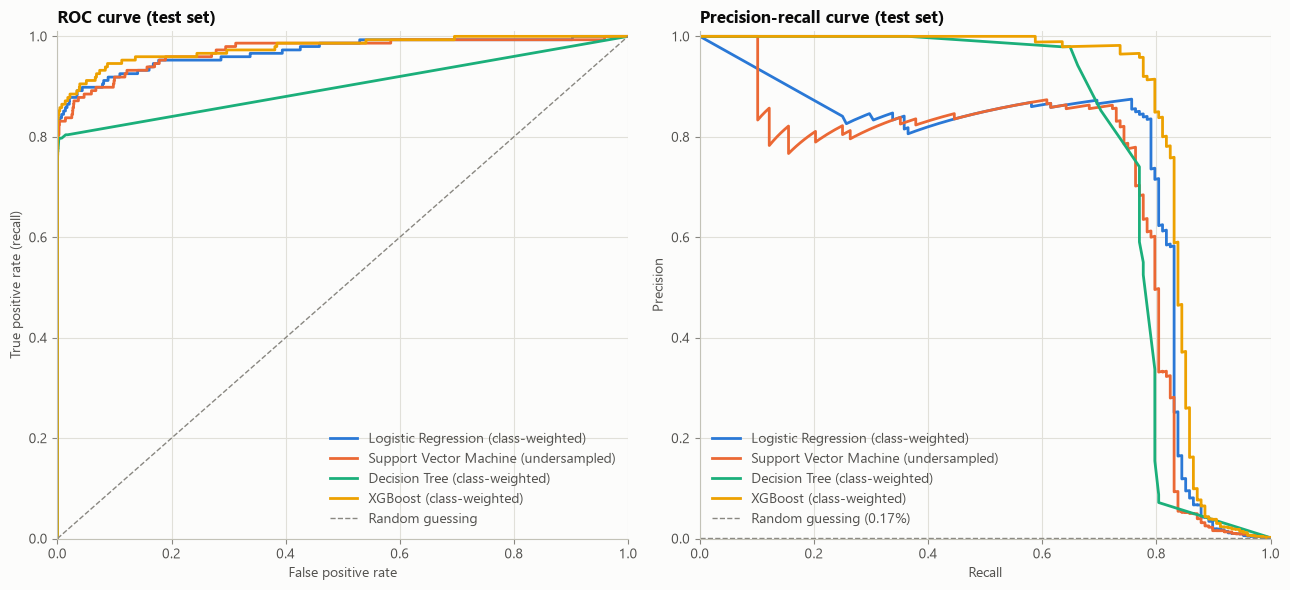

In [21]:
figure, (roc_axes, pr_axes) = plt.subplots(1, 2, figsize=(13, 6))
plotting.plot_roc_curves(final_models, split.X_test, split.y_test, ax=roc_axes)
plotting.plot_precision_recall_curves(final_models, split.X_test, split.y_test, ax=pr_axes)
figure.tight_layout()
plt.show()

## 9. Confusion matrices of the final models

Rows show the true class and columns the predicted class. The bottom-left cell counts **missed frauds**, and the top-right cell counts **false alarms**. Cell shading uses a logarithmic scale so that the small fraud counts remain distinguishable next to the ~85,000 true negatives.

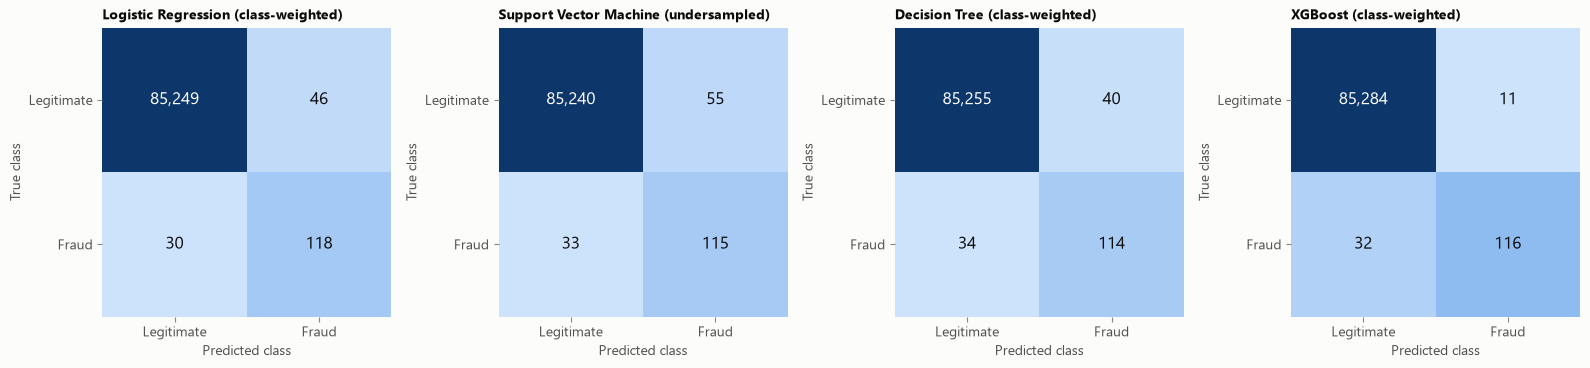

In [22]:
plotting.plot_confusion_matrices(final_models, split.X_test, split.y_test)
plt.show()

## 10. What the tree-based models rely on

Feature importance measures how much each feature reduced the training loss across all splits that use it. It shows which signals the model relies on, not causal effects. Because `V1` to `V28` are anonymised principal components, the names themselves cannot be interpreted. What is informative is whether the two tree-based models agree on which components matter.

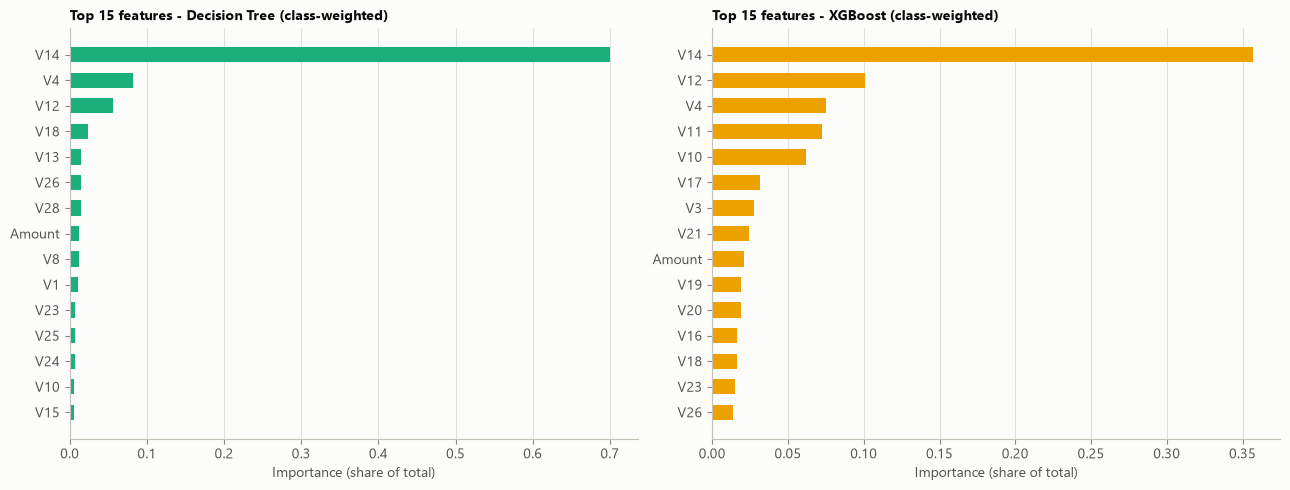

In [23]:
tree_based = [result for result in finalists if result.model_name in (models.DECISION_TREE.name, models.XGBOOST.name)]

figure, axes = plt.subplots(1, len(tree_based), figsize=(6.5 * len(tree_based), 5))
for ax, result in zip(axes, tree_based):
    plotting.plot_feature_importance(result.best_pipeline, result.label, ax=ax)
figure.tight_layout()
plt.show()

## 11. Conclusions

1. **The best model is XGBoost with class weighting.** It has the highest cross-validated average precision (0.864) and the highest test average precision (0.835). At its tuned threshold it catches 116 of the 148 test frauds (78 %) and flags only 11 of the 85,295 legitimate transactions, a precision of 91 %.

2. **Keeping all the data and weighting the classes works better than undersampling.** This held for all three algorithms that were evaluated both ways, most clearly for the tree-based ones. The first version of this notebook concluded the opposite. That conclusion relied on recall alone and on a test set that overlapped with the undersampled training data.

3. **Choosing the threshold matters as much as choosing the algorithm.** For Logistic Regression, the Decision Tree and the SVM, a threshold chosen by cross-validation reduced false alarms by a factor of between 4.5 and 40, while each missed only 5 to 12 more frauds. The default threshold of 0.5 is arbitrary, and with imbalanced classes it is usually far from optimal.

4. **Average precision is a better guide than ROC-AUC for this problem.** ROC-AUC ranked every model between 0.90 and 0.98 and hid differences that average precision and the false-alarm counts make obvious.

5. **The SVM is competitive but does not scale.** Trained on only ~550 rows per fold, it comes close to the linear model (test average precision 0.692 versus 0.703). However, its training cost rules out the full dataset, which is what gives the other models their advantage.

### Limitations

- **The test set contains only 148 frauds.** One fraud is worth 0.7 percentage points of recall, so differences of a few frauds between models are not statistically meaningful. Bootstrap confidence intervals would quantify this.
- **The split is random rather than chronological.** The data covers only two days. In production, a model is trained on the past and applied to the future, and fraud patterns drift over time. A time-based split would give a more conservative estimate.
- **F2 is an assumption about costs.** A real deployment would set the threshold from actual costs, for example the transaction `Amount` lost per missed fraud against the cost of one review.
- **The features are anonymised.** The importance of `V14`, `V12` and `V4` cannot be translated into business rules.

### Possible extensions

- Add SMOTE as a third imbalance strategy inside the same pipeline, for a like-for-like comparison.
- Choose the threshold by minimising an explicit cost function that uses `Amount`.
- Evaluate anomaly-detection methods (Isolation Forest, autoencoders) that learn only from legitimate transactions.
- Validate on a chronological split and report bootstrap confidence intervals for every metric.